# 중마시장 | 독립 근린형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import FIGS, HOUR, TIME_FIGURES, plot_time_weekday
CASE = '중마시장'


## 입지·인근 이동

* 그림: 비공개 시장 위치와 행정동 경계로 작성한 저장 결과
* 재생성: 비공개 입력 경로 지정 시 가능

비공개 시장 위치 입력이 없어 저장된 그림을 표시합니다.


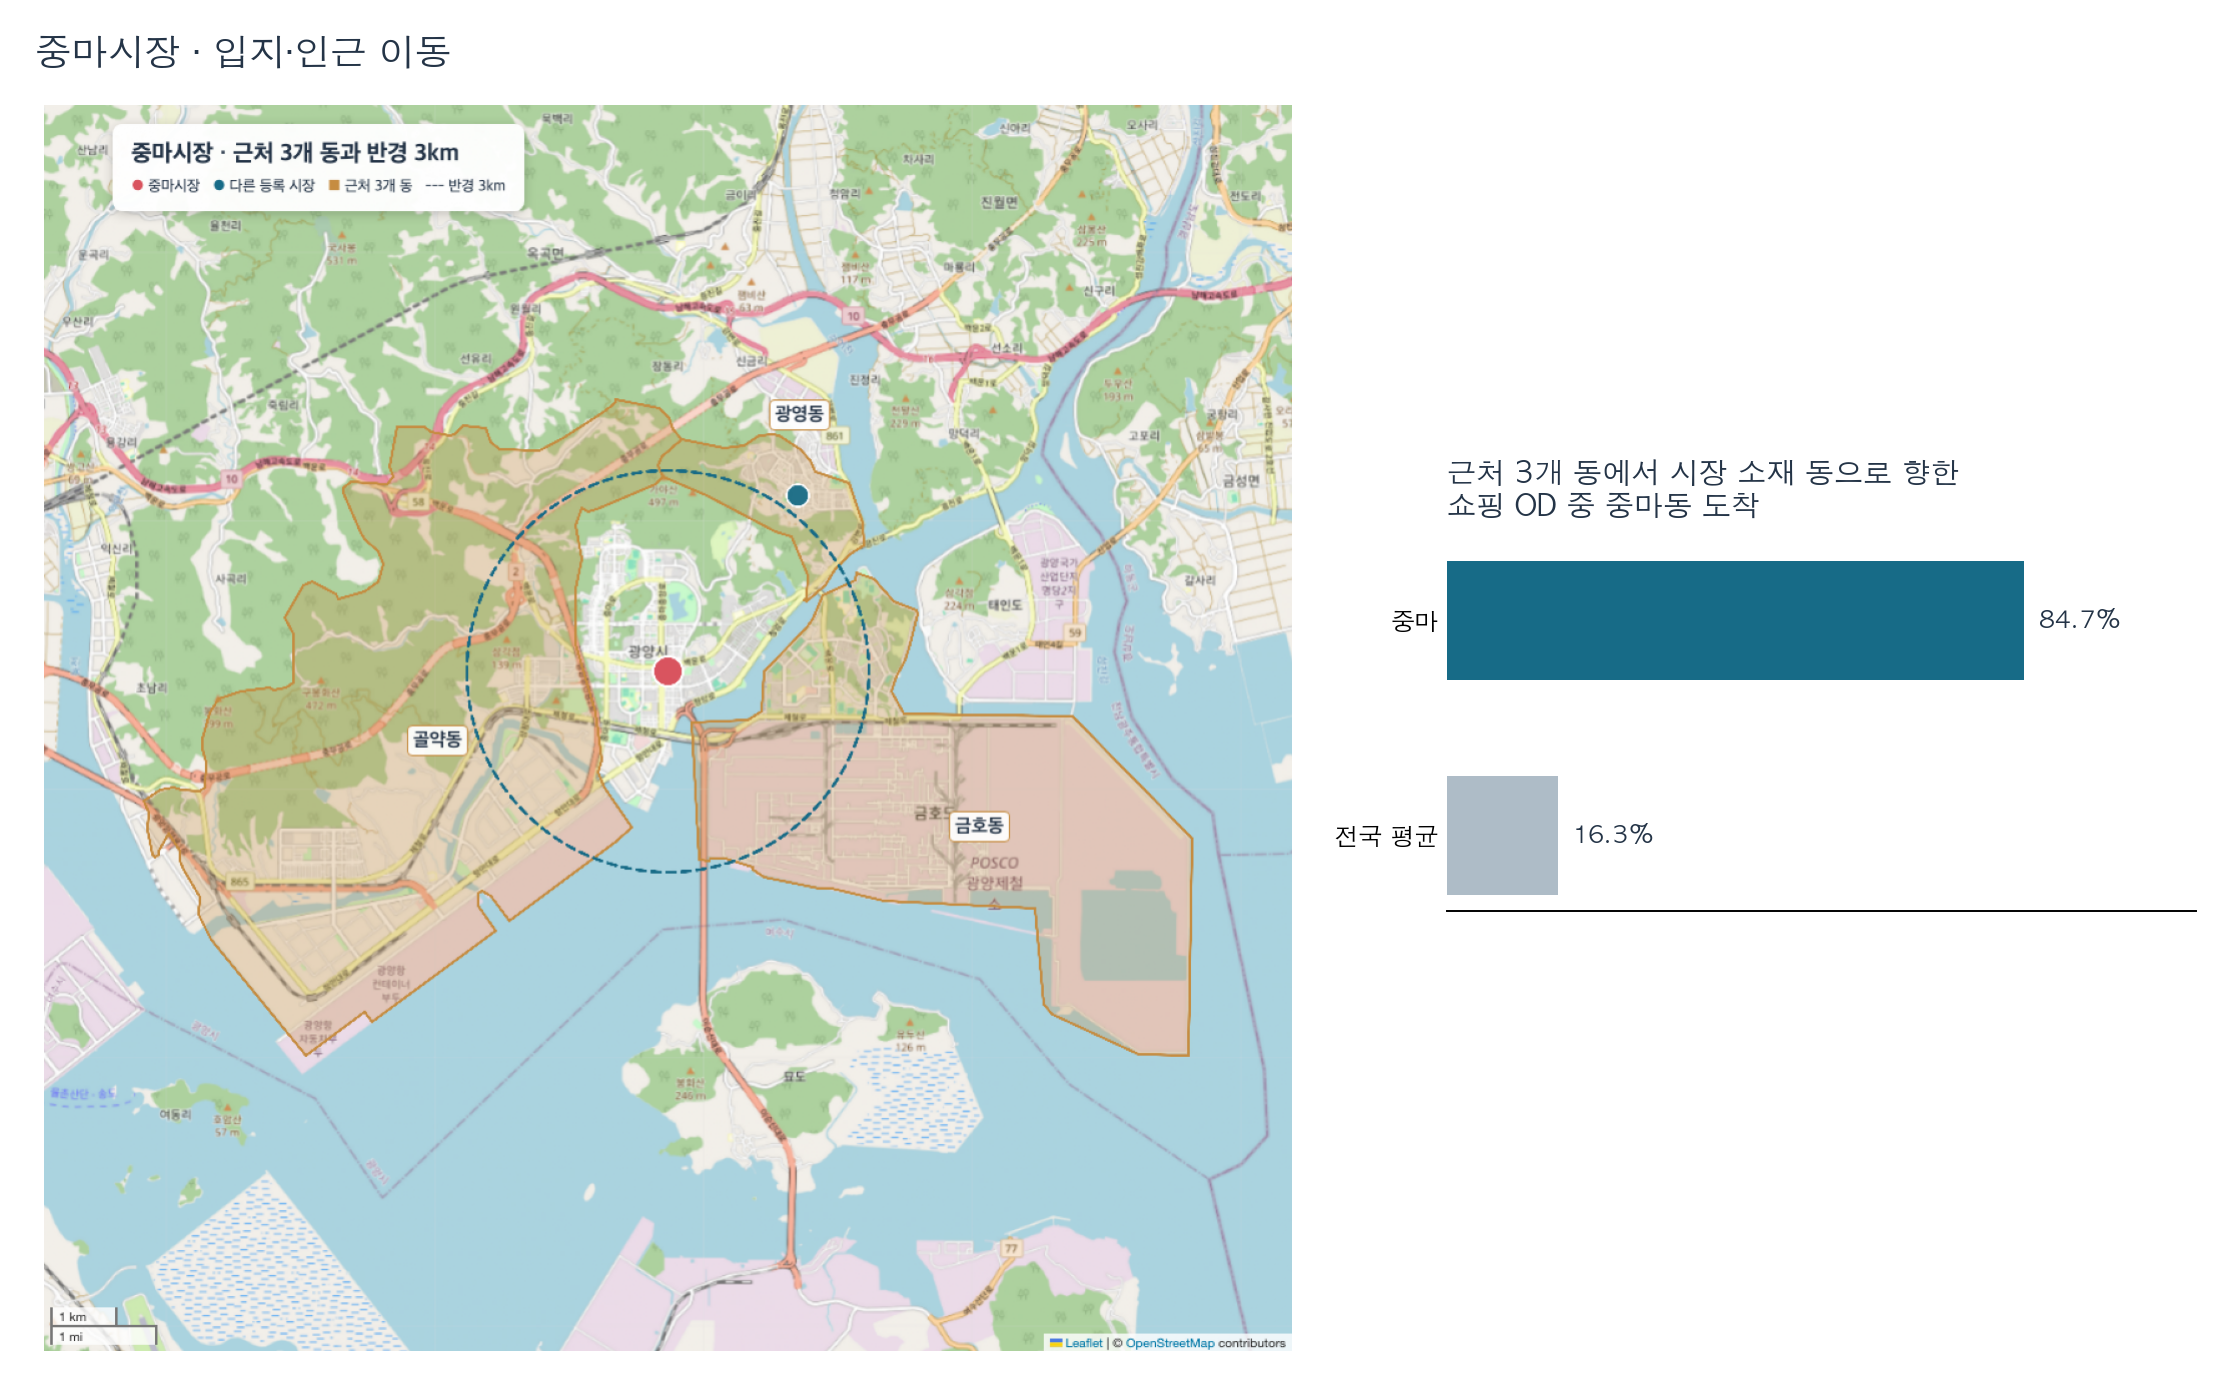

In [2]:
import os, json, tempfile
from plotting import jungma, render_map_png, plot_jungma_nearby
source_paths = [os.environ.get(name) for name in
                ["BC_MARKET_FEATURES", "BC_HDONG_BOUNDARIES", "BC_HDONG_CENTROIDS"]]
if all(p and Path(p).exists() for p in source_paths):
    features = pd.read_csv(source_paths[0], dtype={"행정기관코드": str})
    boundaries = json.loads(Path(source_paths[1]).read_text())
    centroids = pd.read_csv(source_paths[2], dtype={"행정기관코드": str})
    with tempfile.TemporaryDirectory() as folder:
        map_html = jungma(features, boundaries, centroids, Path(folder))
        map_png = Path(folder) / "map.png"
        render_map_png(map_html, map_png, 1000, 1000)
        plot_jungma_nearby(map_png)
else:
    print("비공개 시장 위치 입력이 없어 저장된 그림을 표시합니다.")
display(Image(filename=str(FIGS / "fig_v4_2b_jungma_nearby.png")))

## 요일·시간

,14~16시 비중 (%)
daytype,
주말,23.6
평일,63.1


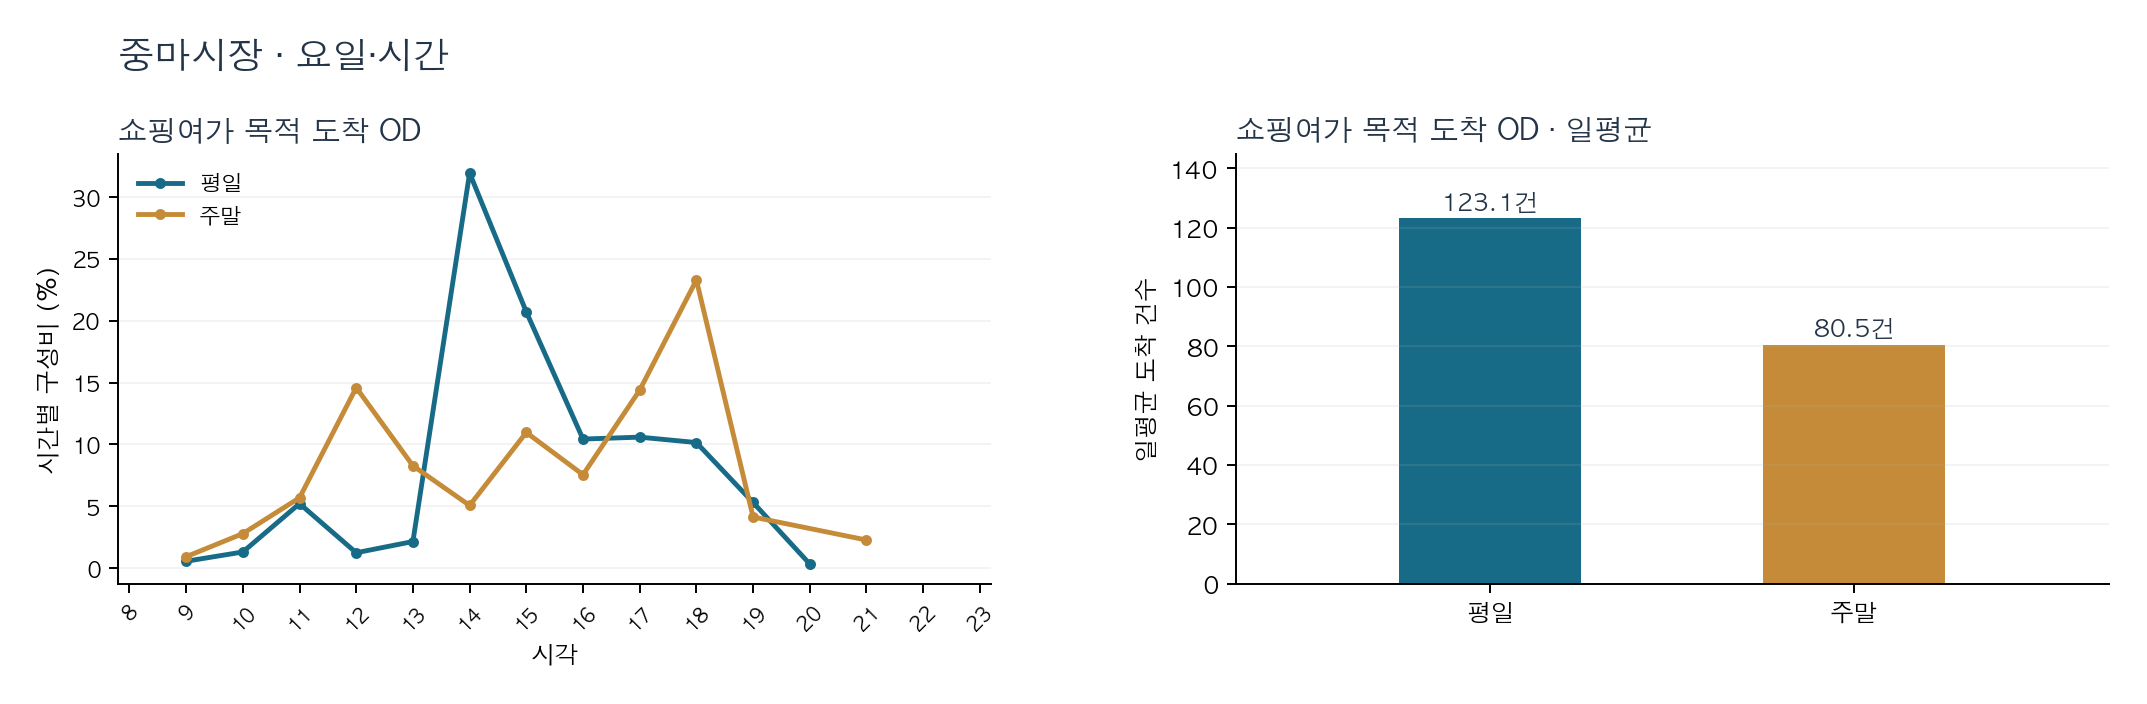

In [3]:
hourly = HOUR.loc[HOUR["case"].eq(CASE) & HOUR["measure"].eq("쇼핑여가 목적 도착 OD")].copy()
afternoon = hourly.loc[hourly["hour"].between(14, 16)].groupby("daytype")["hour_share"].sum() * 100
display(afternoon.round(1).rename("14~16시 비중 (%)").to_frame())
plot_time_weekday(CASE)
display(Image(filename=str(FIGS / TIME_FIGURES[CASE])))

## 제안

* 방안: 평일 14~16시 인근 주민에게 장보기 품목과 영업 점포를 안내하는 시범 운영
* 판정: 시범 시간대 방문객 수와 점포 매출
* 상태: 시행·효과 미확인